[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/exercises/solutions/ex_04_fire_disasters_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🔥 Solutions: Climate-induced disasters: fire mapping
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Turn the burn indices of notebook 04 into the numbers an emergency agency needs — hectares, perimeters and severity — for the December 2024 Franklin fire in Malibu, test how robust they are, and (optionally) compare two Tanager dates to map the January 2025 Palisades fire with dNBR.

These exercises accompany the theme notebook [`04_climate_disasters_fire_flood.ipynb`](../../../notebooks/04_climate_disasters_fire_flood.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Burned-area statistics from NBR and their threshold sensitivity
- From noisy pixels to a fire perimeter with morphology and connected components
- Reading burn-scar spectra: what fire changes and what NBR captures
- Co-registering two scenes on the same grid and computing dNBR
- Why severity is defined on change (dNBR), not on single-date NBR

**Data**
- `20241215_185916_33_4001` — Malibu, California (15 Dec 2024), after the Franklin fire (9–17 Dec 2024)
- *Optional:* `20250123_185518_92_4001` — Santa Monica Mountains (23 Jan 2025), after the Palisades fire

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20241215_185916_33_4001  (Malibu, California, USA)
File       : /home/course/notebooks/20241215_185916_33_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 713 rows × 791 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32611, 30 m pixels
No-data    : 29.0%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 71.0%


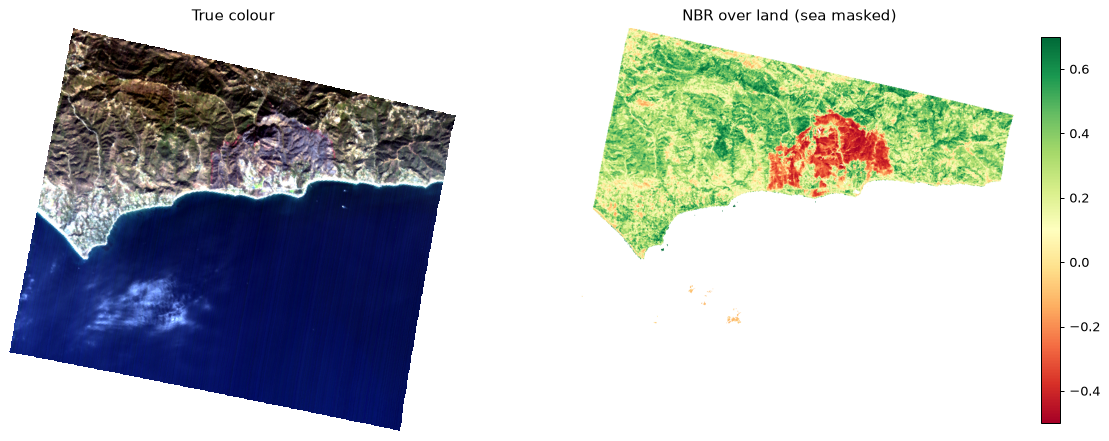

In [2]:
from scipy import ndimage

SCENE_ID = "20241215_185916_33_4001"   # Malibu, California — 15 Dec 2024, days after the Franklin fire
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
R_green, R_red, R_nir, R_swir2 = (scene.read_band(w) for w in (560, 665, 860, 2200))   # as in notebook 04
NBR = hu.nd(R_nir, R_swir2)
NDWI = hu.nd(R_green, R_nir)
sea = valid & (NDWI > 0.1)
land = valid & ~sea
PIXEL_HA = 0.09

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(scene.rgb()); axes[0].set_title("True colour")
im = axes[1].imshow(np.where(land, NBR, np.nan), cmap="RdYlGn", vmin=-0.5, vmax=0.7)
axes[1].set_title("NBR over land (sea masked)"); plt.colorbar(im, ax=axes[1], fraction=0.035)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Exercise 1 — Burned area in hectares  ⭐

1. Count the land pixels with NBR < −0.1 and convert the count to hectares.
2. Reproduce the five severity classes of notebook 04 (NBR ≥ 0.1 unburned; −0.1…0.1 low; −0.27…−0.1
   moderate-low; −0.44…−0.27 moderate-high; < −0.44 high) and make a table of the area per class, over land only.

### Solution

In [3]:
import pandas as pd

burned = land & (NBR < -0.1)
print(f"NBR < -0.1 on land: {burned.sum():,} px = {burned.sum() * PIXEL_HA:,.0f} ha")

bins = [-0.44, -0.27, -0.1, 0.1]
names = ["High", "Moderate-high", "Moderate-low", "Low", "Unburned"]      # digitize 0 … 4
cls = np.digitize(NBR[land], bins)
counts = np.bincount(cls, minlength=5)
pd.DataFrame({"class": names, "pixels": counts, "hectares": counts * PIXEL_HA,
              "% of land": 100 * counts / land.sum()}).round(1)

NBR < -0.1 on land: 14,943 px = 1,345 ha


,class,pixels,hectares,% of land
0,High,1375,123.8,0.8
1,Moderate-high,8069,726.2,4.9
2,Moderate-low,5499,494.9,3.4
3,Low,19210,1728.9,11.8
4,Unburned,129149,11623.4,79.1


**Interpretation:** about 1,300 ha of land have NBR < −0.1, which is the order of magnitude of the Franklin
fire (reported by CAL FIRE as roughly 4,000 acres ≈ 1,600 ha). Remember that these are single-date NBR
thresholds: pixels are "burned" because they look burned *today*. Rock, roads, roofs and bare soil can also have
low NBR, which is why operational severity mapping uses the pre/post difference, dNBR (Exercise 5).

## Exercise 2 — How sensitive is the burned area to the threshold?  ⭐⭐

Plot the burned area (ha) as a function of the NBR threshold, from −0.5 to +0.2. Mark the value −0.1 used above.
Where is the curve flat (the estimate is robust) and where is it steep? What does a steep section mean
physically?

### Solution

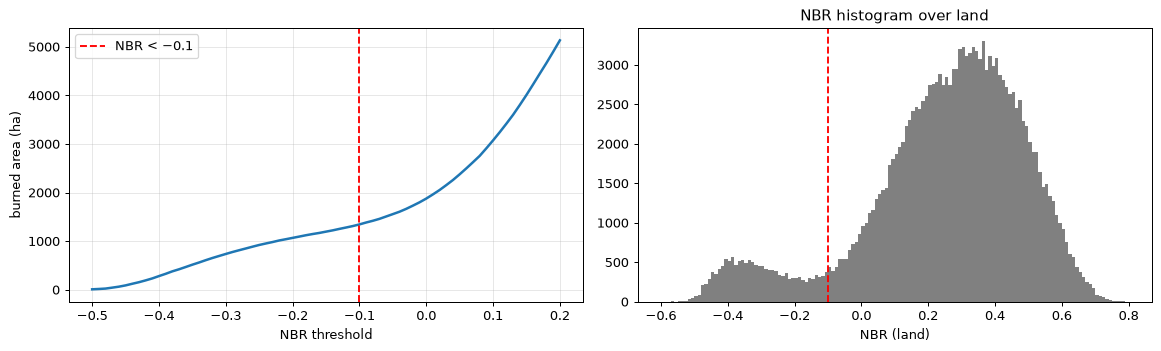

In [4]:
ts = np.linspace(-0.5, 0.2, 71)
area = np.array([(land & (NBR < t)).sum() * PIXEL_HA for t in ts])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ts, area, lw=2); axes[0].axvline(-0.1, color="r", ls="--", label="NBR < −0.1")
axes[0].set_xlabel("NBR threshold"); axes[0].set_ylabel("burned area (ha)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].hist(NBR[land], bins=140, range=(-0.6, 0.8), color="grey")
axes[1].axvline(-0.1, color="r", ls="--"); axes[1].set_xlabel("NBR (land)"); axes[1].set_title("NBR histogram over land")
plt.tight_layout(); plt.show()

**Interpretation:** the area curve rises slowly between about −0.5 and −0.1: the burned pixels form a
separate low-NBR mode in the histogram. It then climbs steeply above ~0, where the threshold starts cutting into
the large population of sparsely vegetated but *unburned* land (dry chaparral, grass, rock and roads in
December). A threshold inside the gap between the two modes gives a robust estimate. A threshold in the steep
part mostly measures how many dry, unburned surfaces you misclassify.

## Exercise 3 — From pixels to a fire perimeter  ⭐⭐

Agencies report fires as **polygons** (perimeters), not as scattered pixels.

1. Clean the `NBR < −0.1` mask with a morphological **closing** (2 iterations) to fill small unburned gaps.
2. Label the connected regions and keep the largest one — the Franklin fire scar.
3. Report its area and compare it with the ~1,630 ha (4,000 acres) reported by CAL FIRE. Draw its outline on the
   true-colour image.
4. Why might your area be smaller or larger than the official one?

### Solution

155 regions; largest = 1,386 ha (85% of the ~1,630 ha reported by CAL FIRE)


centroid: 34.0522 N, -118.6968 E


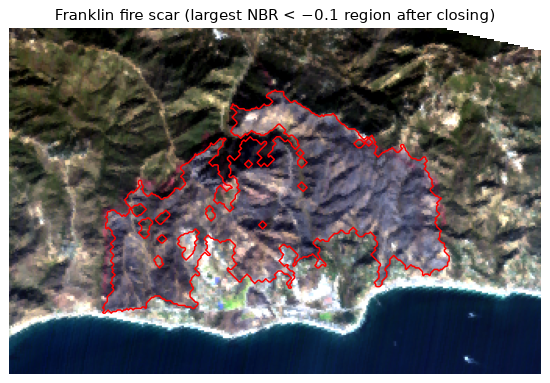

In [5]:
mask = land & (NBR < -0.1)
closed = ndimage.binary_closing(mask, iterations=2)
labels, n = ndimage.label(closed)
sizes = ndimage.sum(closed, labels, range(1, n + 1))
scar = labels == (np.argmax(sizes) + 1)
print(f"{n} regions; largest = {scar.sum() * PIXEL_HA:,.0f} ha "
      f"({scar.sum() * PIXEL_HA / 1630:.0%} of the ~1,630 ha reported by CAL FIRE)")

rows, cols = np.nonzero(scar)
lon, lat = scene.rowcol_to_lonlat(int(rows.mean()), int(cols.mean()))
print(f"centroid: {lat[0]:.4f} N, {lon[0]:.4f} E")

r0, r1, c0, c1 = rows.min() - 40, rows.max() + 40, cols.min() - 60, cols.max() + 60
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(scene.rgb(window=(r0, r1, c0, c1)))
ax.contour(scar[r0:r1, c0:c1], [0.5], colors="red", linewidths=1.2)
ax.set_title("Franklin fire scar (largest NBR < −0.1 region after closing)"); ax.axis("off")
plt.show()

**Interpretation:** the largest region covers about 1,400 ha, around 85% of the official figure, centred on
Malibu Canyon and Pepperdine University. Differences are expected:
- Official perimeters enclose **unburned islands** and low-severity edges that a spectral threshold misses.
- Some burned area may be outside the valid footprint, or hidden by smoke.
- 30 m pixels on the edge are mixed.
- Perimeters are often mapped from aircraft infrared at night, with a different definition of "burned".
Such reasons belong in the "limitations" section of any project.

## Exercise 4 — Burn scar vs chaparral: the spectra behind NBR  ⭐⭐

Plot the mean spectrum (± one standard deviation) of burned land (NBR < −0.15) and of unburned chaparral /
shrubland (NBR > 0.3). Mark the NBR bands (860 and 2200 nm). Which spectral changes caused by the fire does NBR
capture, and which does it ignore?

### Solution

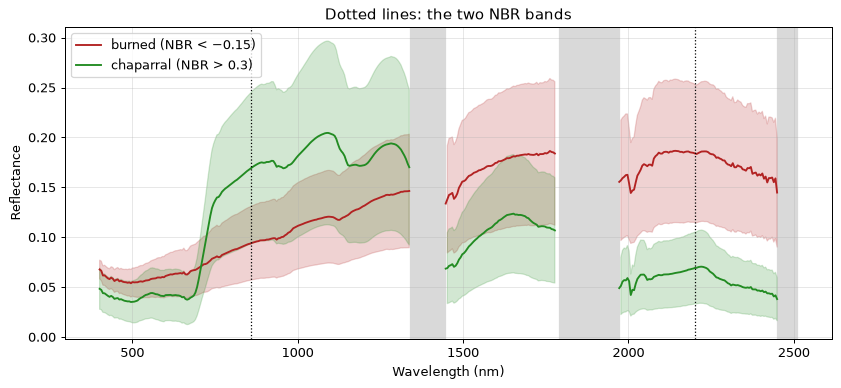

In [6]:
def sample_spectra(mask, n=500):
    rows, cols = np.nonzero(mask)
    pick = np.random.default_rng(0).choice(len(rows), size=min(n, len(rows)), replace=False)
    rows, cols = rows[pick], cols[pick]
    cube, wl = scene.read_cube((rows.min(), rows.max() + 1, cols.min(), cols.max() + 1))
    return cube[:, rows - rows.min(), cols - cols.min()].T, wl

fig, ax = plt.subplots(figsize=(11, 4.5))
hu.shade_bad_regions(ax)
for name, m, color in (("burned (NBR < −0.15)", land & (NBR < -0.15), "firebrick"),
                       ("chaparral (NBR > 0.3)", land & (NBR > 0.3), "forestgreen")):
    S, wl = sample_spectra(m)
    mu, sd = np.nanmean(S, axis=0), np.nanstd(S, axis=0)
    hu.plot_spectrum(ax, wl, mu, color=color, label=name)
    gap = np.diff(wl, prepend=wl[0]) > 20
    ax.fill_between(wl, mu - sd, mu + sd, color=color, alpha=0.2, where=~gap)
for w in (860, 2200):
    ax.axvline(w, color="k", ls=":", lw=1)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Dotted lines: the two NBR bands")
plt.show()

**Interpretation:** fire removes the leaves and their chlorophyll and water, and leaves char and ash behind.
- In the **NIR** (860 nm) the burned surface is much darker, because the scattering leaf structure is gone.
- In the **SWIR** it is *brighter*: without leaf water, the soil and ash show through, so the reflectance keeps
  rising towards 2200 nm.
- The **red edge** disappears and the leaf-water absorptions at ~970 and ~1200 nm vanish.
- The spectrum becomes a smooth, rising "soil and char" curve (compare `burn_scar` in the course library).

NBR uses exactly the two strongest contrasts, NIR down and SWIR-2 up. It ignores the disappearance of the red
edge and the ash colour in the visible, which hyperspectral data can use to separate char (dark) from white ash
(complete combustion), and to estimate residual green vegetation fractions.

## Exercise 5 — Before and after: dNBR with a second Tanager scene (optional)  ⭐⭐⭐

Tanager imaged the same coast again on **23 January 2025** (`20250123_185518_92_4001`), after the Palisades
fire of 7 January 2025. That scene is not part of the standard course download (~1.3 GB). Set
`DOWNLOAD_POST = True` to fetch it, or skip this exercise.

1. Both scenes are on the same UTM grid (EPSG:32611, 30 m). Use their geotransforms to compute the row/column
   offset between them and cut the overlapping area out of both NBR maps.
2. Check the co-registration: do the coastlines (NDWI > 0.1) line up?
3. Compute dNBR = NBR(15 Dec) − NBR(23 Jan) over land in both dates and classify it with the USGS thresholds
   (Key & Benson, 2006): < 0.1 unburned, 0.1–0.27 low, 0.27–0.44 moderate-low, 0.44–0.66 moderate-high,
   > 0.66 high.
4. What is dNBR inside the Franklin scar, and why? Where is the new burn?

### Solution

In [7]:
POST_ID = "20250123_185518_92_4001"
DOWNLOAD_POST = False   # set True to download ~1.3 GB from Planet's STAC catalogue

have_post = hu.find_local(POST_ID) is not None or DOWNLOAD_POST
if not have_post:
    print("Post-fire scene not available locally — set DOWNLOAD_POST = True to run this exercise.")
else:
    post = hu.get_scene(POST_ID)
    pre_t, post_t = scene.transform(), post.transform()
    # A pixel at pre (row, col) sits at post (row + row_off, col + col_off)
    row_off = int(round((post_t.f - pre_t.f) / scene.res_y))   # y of the upper-left corners (northing)
    col_off = int(round((pre_t.c - post_t.c) / scene.res_x))   # x of the upper-left corners (easting)
    print(f"post pixel = pre pixel + ({row_off} rows, {col_off} cols)")
    # overlapping window in pre coordinates, then the same window in post coordinates
    r0, r1 = max(0, -row_off), min(scene.shape[1], post.shape[1] - row_off)
    c0, c1 = max(0, -col_off), min(scene.shape[2], post.shape[2] - col_off)
    pre_win = (r0, r1, c0, c1)
    post_win = (r0 + row_off, r1 + row_off, c0 + col_off, c1 + col_off)
    print("pre window:", pre_win, " post window:", post_win)

    def nbr_ndwi(sc, win):
        n, s2, g = (sc.read_band(w, window=win) for w in (860, 2200, 560))
        return hu.nd(n, s2), hu.nd(g, n)
    nbr_pre, ndwi_pre = nbr_ndwi(scene, pre_win)
    nbr_post, ndwi_post = nbr_ndwi(post, post_win)
    both = np.isfinite(ndwi_pre) & np.isfinite(ndwi_post)
    print(f"coastline agreement (NDWI > 0.1 in both dates): {((ndwi_pre > 0.1) == (ndwi_post > 0.1))[both].mean():.1%}")

post pixel = pre pixel + (295 rows, -114 cols)
pre window: (0, 713, 114, 791)  post window: (295, 1008, 0, 677)


coastline agreement (NDWI > 0.1 in both dates): 99.5%


Unburned          4,662 ha
Low               2,375 ha
Moderate-low        798 ha
Moderate-high     1,012 ha
High              1,123 ha

median dNBR inside the Franklin scar: -0.018


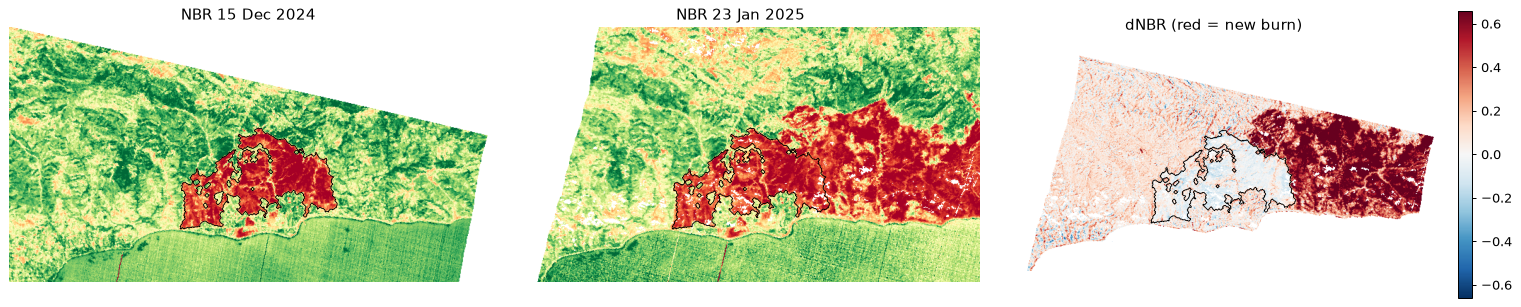

In [8]:
if have_post:
    dNBR = np.where((ndwi_pre < 0.1) & (ndwi_post < 0.1), nbr_pre - nbr_post, np.nan)
    usgs_bins = [0.1, 0.27, 0.44, 0.66]
    usgs_names = ["Unburned", "Low", "Moderate-low", "Moderate-high", "High"]
    ok = np.isfinite(dNBR)
    counts = np.bincount(np.digitize(dNBR[ok], usgs_bins), minlength=5)
    for nme, c in zip(usgs_names, counts):
        print(f"{nme:14s} {c * PIXEL_HA:8,.0f} ha")
    franklin = scar[pre_win[0]:pre_win[1], pre_win[2]:pre_win[3]]
    print(f"\nmedian dNBR inside the Franklin scar: {np.nanmedian(dNBR[franklin]):+.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, img, title in ((axes[0], nbr_pre, "NBR 15 Dec 2024"), (axes[1], nbr_post, "NBR 23 Jan 2025")):
        ax.imshow(img, cmap="RdYlGn", vmin=-0.4, vmax=0.6); ax.set_title(title)
    im = axes[2].imshow(dNBR, cmap="RdBu_r", vmin=-0.66, vmax=0.66); axes[2].set_title("dNBR (red = new burn)")
    plt.colorbar(im, ax=axes[2], fraction=0.03)
    for ax in axes:
        ax.contour(franklin, [0.5], colors="k", linewidths=0.7); ax.set_ylim(360, 0); ax.axis("off")
    plt.tight_layout(); plt.show()

**Interpretation**
- The two grids share the same UTM zone and 30 m pixel size, so co-registration reduces to an **integer
  offset**. The coastlines agree for more than 99% of the pixels, which is good enough for pixel-wise
  differencing. With other sensors you would first reproject and resample onto a common grid.
- Inside the Franklin scar (black outline), dNBR ≈ 0: the area had already burned before the first image, so
  nothing changed.
- The **new burn** starts right at the scar's eastern edge and extends east with high dNBR (median ≈ 0.6). This
  is the western part of the **Palisades fire** (January 2025), which burned from Pacific Palisades westward
  into eastern Malibu. Only part of that fire lies inside the overlap. The fresh Franklin scar, with little
  fuel left, sits right at the western edge of the new burn — recent burn scars can act as fuel breaks.
- Outside the burns, dNBR is slightly positive (~0.05), caused by illumination, phenology and atmospheric
  differences between the dates. That is why the USGS "unburned" class extends up to 0.1.

## Exercise 6 — Reflection — NBR, dNBR and what else is dark in the SWIR  ⭐

Answer in a short markdown cell:

1. Why are the burn-severity thresholds of Key & Benson (2006) defined for **dNBR** and not for single-date NBR?
2. Name three non-burned surfaces that can have NBR < 0 in a single image, and one way to exclude each of them.
3. How soon after a fire should the post-fire image be taken, and why does it matter?

### Solution

**Model answer**
1. Single-date NBR mixes **what was there** with **what happened**: a naturally sparse, rocky slope and a
   severely burned forest can have the same post-fire NBR. dNBR subtracts the pre-fire state, so it measures
   the *change* caused by the fire, which is what severity describes. (Relative versions, RdNBR and RBR, also
   correct for pre-fire vegetation density.)
2. (a) **Water**: mask with NDWI or MNDWI. (b) **Urban surfaces, roads and roofs**: mask with a built-up layer
   (WorldCover 50) or check that they were also dark *before* the fire. (c) **Bare rock and soil, or dry grass
   and fallow fields**: these are dark in the NIR but were already dark before the fire, so dNBR removes them.
   Shadows on steep north-facing slopes in winter are another trap — use the sun geometry and a DEM.
3. For an *initial assessment*, within days to a few weeks, before rain moves the ash and the vegetation starts
   to recover. For an *extended assessment* (typical in the USA), in the next growing season, to capture
   delayed tree mortality. The timing changes the numbers, so always report the dates of both images.

## Key takeaways

- Burned-area numbers depend on the threshold — look for the gap in the NBR histogram.
- Morphology and connected components turn pixel masks into reportable perimeters.
- Fire darkens the NIR and brightens the SWIR; hyperspectral data also sees the lost red edge and leaf water.
- Scenes on the same grid can be differenced after an integer offset; always check registration first.
- Severity thresholds apply to dNBR; single-date NBR confuses burns with rock, roads and water.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC